In [23]:
import sys
sys.path.append("..")
import pandas as pd

import matplotlib.pyplot as plt
import statsmodels.api as sm

from src.data import load_brent_spot, load_brent_futures
from src.models import random_walk_forecast, ar1_forecast, historical_mean_forecast
from src.features import log_returns, realised_volatility
from src.backtest import walk_forward
from src.metrics import compare_models

Test Spot loading

<Axes: xlabel='DATE'>

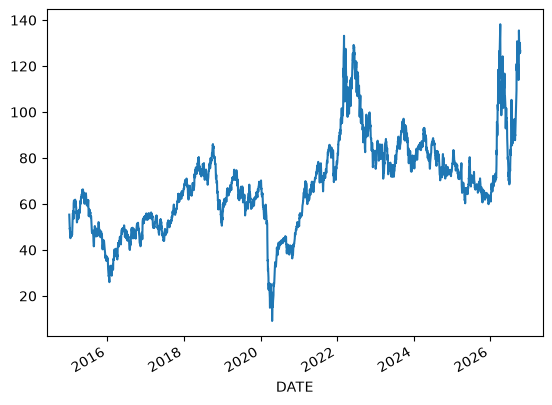

In [2]:
spot = load_brent_spot(start="2015-01-01")
spot.tail()
spot["brent_spot"].plot()

Test Futures loading

<Axes: xlabel='Date'>

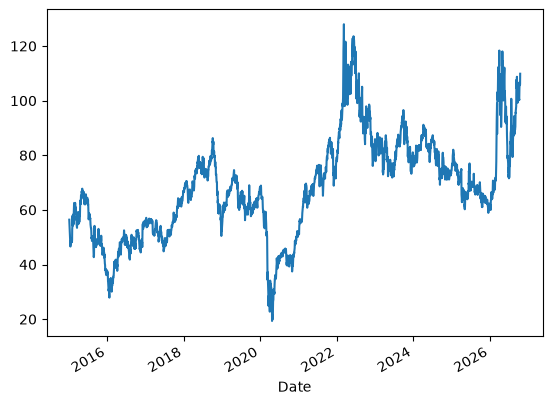

In [2]:
futures = load_brent_futures(start="2015-01-01")
futures.tail()
futures["brent_futures"].plot()

Test log_returns function

DATE
2015-01-02         NaN
2015-01-05   -0.080825
2015-01-06   -0.018973
2015-01-07   -0.021376
2015-01-08    0.007513
                ...   
2026-10-08    0.032636
2026-10-09   -0.001153
2026-10-12   -0.000615
2026-10-13   -0.032615
2026-10-14    0.006103
Name: brent_spot, Length: 2992, dtype: float64


<Axes: xlabel='DATE'>

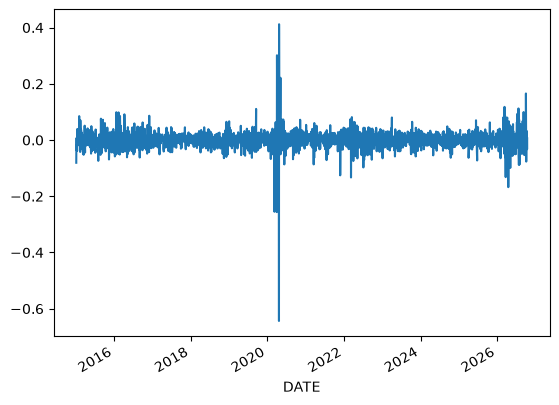

In [5]:
from src.features import log_returns

returns = log_returns(spot)
print(returns)
returns.plot()

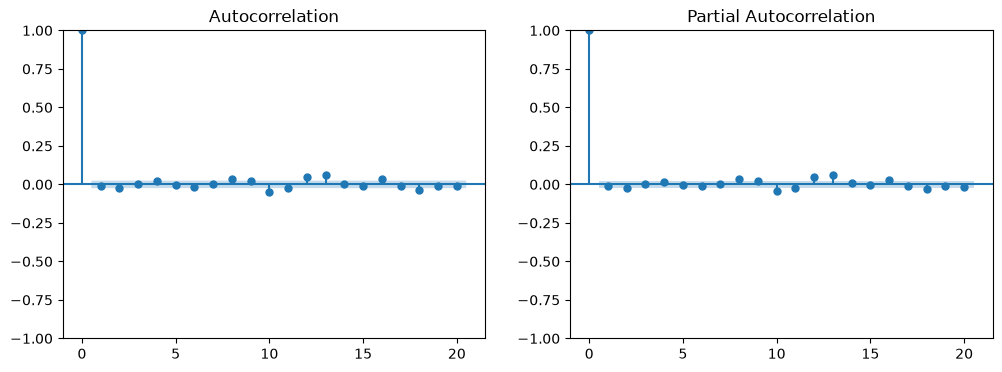

In [ ]:
spot = load_brent_spot(start="2000-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sm.graphics.tsa.plot_acf(data["log_return"], lags=20, ax=axes[0])
sm.graphics.tsa.plot_pacf(data["log_return"], lags=20, ax=axes[1])
plt.show()


No significant correlation at any lag.

ACF/PACF are run on log returns (differenced log prices), because log prices are not stationary. An ARMA(p,q) on log returns is the same model as an ARIMA(p,1,q) on log prices. The ACF/PACF are flat, so p = q = 0: ARIMA(0,1,0), which is the random walk.

Next to determine size of training set.

In [25]:
spot = load_brent_spot(start="1987-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

lookback_candidates = [500, 1000, 2000, 3000, 5000, 7000]

summary = []
for lb in lookback_candidates:
    res = walk_forward(
        data,
        horizon=1,
        start_date="2024-01-01",
        end_date="2026-09-30",
        forecast_funct=ar1_forecast,
        lookback=lb,
    )
    err = res["actual"] - res["forecast"]
    mae = err.abs().mean()
    rmse = (err ** 2).mean() ** 0.5
    mape = (err.abs() / res["actual"]).mean() * 100
    summary.append({"lookback": lb, "MAE": mae, "RMSE": rmse, "MAPE": mape})

summary_df = pd.DataFrame(summary)
summary_df.sort_values("RMSE")

,lookback,MAE,RMSE,MAPE
5,7000,1.605002,2.574101,1.883837
4,5000,1.605029,2.574398,1.883615
3,3000,1.606162,2.574741,1.884760
2,2000,1.607173,2.574897,1.886152
1,1000,1.608775,2.584055,1.887808
0,500,1.612439,2.590181,1.891491


Notice while increasing lookback (training set), the MAPE converges. With more training set, averaged coeff for c and φ (in  c + φ × yesterday's return) both averaged to 0. Therefore forecast is 0 return, which is the same as random walk (tmr price is simply todays price). Will use lookback = 3000 to balance cost of running large training each time.

Test RW, Historical mean (as benchmarks per project brief), and AR1

In [26]:
spot = load_brent_spot(start="2000-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

rw_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2026-09-30", forecast_funct=random_walk_forecast)
ar1_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2026-09-30", forecast_funct=ar1_forecast, lookback=3000)
mean_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2026-09-30", forecast_funct=historical_mean_forecast, lookback=3000)

vol = realised_volatility(data)

results_dict = {
    "Random Walk": rw_results,
    "AR(1), lb=2000": ar1_results,
    "Historical Mean": mean_results,
}

compare_models(results_dict)


,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.604216,2.574188,1.882614,0.004317,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
"AR(1), lb=2000",1.606162,2.574741,1.884760,0.467626,0.468504,0.338068,0.392739,0.46712,0.605882,0.527529,-0.429513,-0.992827,-0.823089,601.0
Historical Mean,1.604547,2.574617,1.882930,0.490647,0.506667,0.107955,0.177986,0.48871,0.891176,0.631250,-0.438655,-1.014259,-0.848524,31.0


Check calendar effect next, if any single day can be used as a dummy variable.

Investigate seasonality/calendar effect

                 mean       std  count
day_of_week                           
0           -0.000979  0.027625   1735
1           -0.000804  0.028662   1836
2            0.000413  0.027387   1856
3            0.001378  0.026665   1867
4            0.000967  0.024460   1813
           mean       std  count
month                           
1      0.000812  0.030280    748
2      0.001043  0.022293    706
3      0.000003  0.033208    769
4      0.001852  0.042553    706
5      0.000269  0.023935    751
6      0.000235  0.022312    777
7      0.001098  0.021535    800
8      0.000379  0.022228    801
9      0.000534  0.025171    777
10    -0.001479  0.025146    793
11    -0.000863  0.024194    754
12    -0.001235  0.025181    725


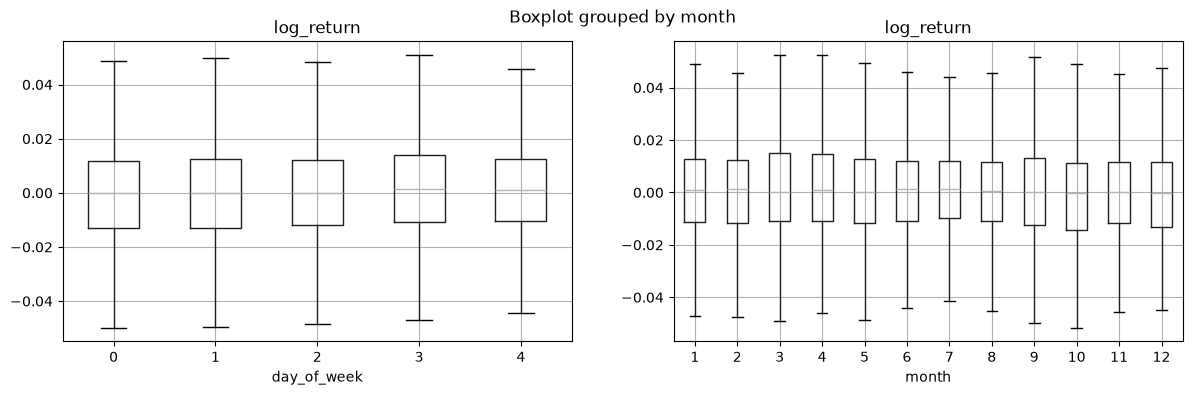

In [8]:
from scipy.stats import kruskal

spot = load_brent_spot(start="1987-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

seasonal = data.copy()
seasonal["day_of_week"] = seasonal.index.dayofweek # (0=Monday, 4=Friday)
seasonal["month"] = seasonal.index.month

print(seasonal.groupby("day_of_week")["log_return"].agg(["mean", "std", "count"])) # do groupby day/month
print(seasonal.groupby("month")["log_return"].agg(["mean", "std", "count"]))

fig, axes = plt.subplots(1,2,figsize = (14, 4))
seasonal.boxplot(column="log_return", by="day_of_week", ax=axes[0], showfliers=False)
seasonal.boxplot(column="log_return", by="month", ax=axes[1], showfliers=False)
plt.show()

In [12]:
groups_days = [g["log_return"].values for _, g in seasonal.groupby("day_of_week")]
groups_months = [g["log_return"].values for _, g in seasonal.groupby("month")]

print("Day of week dist:", kruskal(*groups_days))
print("Months dist:", kruskal(*groups_months))

Day of week dist: KruskalResult(statistic=np.float64(13.57456740858555), pvalue=np.float64(0.00878427932615768))
Months dist: KruskalResult(statistic=np.float64(14.83740304946368), pvalue=np.float64(0.19006237574170223))


P-value for day of week seem significant since p-val < 0.05. 

In [16]:
# For whole training set
pre_val_period = seasonal[seasonal.index < "2024-01-01"]

groups = [g["log_return"].values for _, g in pre_val_period.groupby("day_of_week")]
print(kruskal(*groups))
print(pre_val_period.groupby("day_of_week")["log_return"].agg(["mean", "std", "count"]))


# Recent years of training set
recent_pre_val_period = seasonal[(seasonal.index >= "2015-01-01") & (seasonal.index < "2024-01-01")]

groups = [g["log_return"].values for _, g in recent_pre_val_period.groupby("day_of_week")]
print(kruskal(*groups))
print(recent_pre_val_period.groupby("day_of_week")["log_return"].agg(["mean", "std", "count"]))




KruskalResult(statistic=np.float64(12.474617678986375), pvalue=np.float64(0.014149734625531584))
                 mean       std  count
day_of_week                           
0           -0.000874  0.027493   1602
1           -0.001003  0.028743   1690
2            0.000548  0.027502   1712
3            0.001160  0.026630   1725
4            0.000948  0.023948   1672
KruskalResult(statistic=np.float64(2.7440294326678334), pvalue=np.float64(0.601532308959124))
                 mean       std  count
day_of_week                           
0           -0.001989  0.030997    434
1           -0.001709  0.040914    462
2            0.001760  0.033333    466
3            0.000819  0.028922    468
4            0.001732  0.026302    456


While the days have different return means, compared to the noise 2%, its a tiny difference. (e.g. Thursday (+0.12%)vs Monday (-ve 0.1%) is < 0.22%, but std devatiation (noise) is ~ 2.7%)

Converted to price: forecast = today's price × exp(predicted return). On a $100 barrel:

Thursday: 100 × exp(0.00116) ≈ $100.12
Tuesday: 100 × exp(−0.001003) ≈ $99.90
Random walk: $100.00
So the dummy moves the forecast by about 10–12 cents.

Our RW MAE is around $1.60. So a dummy variable shifting by 10cents wont greatly reduce our MAE. There no reason to add calendar effect also.

Additionally, if you isolate for recent years only, the p-value > 0.05, and no weekday is significant.



Testing frozen fitting after Oct 1 2026.

In [10]:
import sys
sys.path.append("..")

from src.data import load_brent_spot
from src.features import log_returns
from src.models import random_walk_forecast, ar1_forecast, historical_mean_forecast
from src.backtest import walk_forward
from src.metrics import compare_models

spot = load_brent_spot(start="1987-01-01")
data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()


test_args = dict(horizon=1, start_date="2026-10-01", end_date="2026-10-23",
                 fit_end_date="2026-09-30", target_end_date="2026-10-23")

test_results = {
    "Random Walk": walk_forward(data, forecast_funct=random_walk_forecast, **test_args),
    "AR(1), lb=5000": walk_forward(data, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    "Historical Mean": walk_forward(data, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
}

compare_models(test_results)


,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,4.000000,6.941615,3.126341,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,NaN,0.000000,0.0
"AR(1), lb=5000",3.989349,6.896861,3.118900,0.461538,0.363636,1.0,0.533333,1.0,0.222222,0.363636,3.354099,3.581547,-0.114074,9.0
Historical Mean,4.008775,6.942169,3.133637,0.307692,0.307692,1.0,0.470588,0.0,0.000000,0.000000,0.463949,0.482371,-0.149731,1.0


Adding Endogenous variables to test VAR model.

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from statsmodels.tsa.api import VAR
from src.data import load_dataset

In [ ]:
data = load_dataset()
data.apply(lambda s: s.first_valid_index())   # first date each column has data

brent_spot   1987-05-20
wti          1987-05-20
usd          2006-01-03
vix          1990-01-02
ovx          2007-05-10
epu          1987-05-20
sp500        1987-05-20
gpr          1987-05-20
dtype: datetime64[us]

In [3]:
data.head()

,brent_spot,wti,usd,vix,ovx,epu,sp500,gpr
DATE,,,,,,,,
1987-05-20,18.63,19.75,NaN,NaN,NaN,17.22,278.209991,106.857018
1987-05-21,18.45,19.95,NaN,NaN,NaN,17.60,280.170013,77.517189
1987-05-22,18.55,19.68,NaN,NaN,NaN,18.80,282.160004,132.502701
1987-05-25,18.60,19.68,NaN,NaN,NaN,36.05,282.160004,87.685616
1987-05-26,18.63,19.35,NaN,NaN,NaN,27.44,289.109985,82.439468


usd ans ovx start on 2006 and 2007 respectively. dropna therefore makes training pool from 2007.

In [4]:
PRICES = ["brent_spot", "wti", "usd", "sp500"]   # prices -> log returns for stationarity
INDICES = ["vix", "ovx", "epu", "gpr"]  

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
X = X.dropna()                         # sample now starts when the last variable (OVX) starts
pre = X[X.index < "2024-01-01"]        # test only on data before validation, so no peeking
pre.shape                           

/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


(4197, 8)

In [5]:
band = 2 / np.sqrt(len(pre))
ccm = pd.DataFrame(
    {col: [pre["brent_spot"].corr(pre[col].shift(k)) for k in range(1, 6)] for col in pre.columns},
    index=range(1, 6),
)
ccm.index.name = "lag k"
print(f"significant if |corr| > {band:.3f}")
ccm.round(3)


significant if |corr| > 0.031


,brent_spot,wti,usd,sp500,vix,ovx,epu,gpr
lag k,,,,,,,,
1,0.063,0.169,0.004,0.088,-0.017,0.015,0.039,-0.014
2,-0.017,0.067,-0.006,0.009,-0.003,0.025,0.042,-0.009
3,-0.007,0.086,-0.006,-0.016,0.002,0.026,0.037,-0.011
4,0.016,0.015,-0.022,0.032,0.005,0.037,0.033,-0.026
5,-0.010,-0.037,0.007,0.000,0.007,0.036,0.020,-0.026


See todays brent got some correlation to the lag 1's of WTI and SP500 (and epu boredline). Potentially because US markets close later than london Brent, so Brent only reacts the following day.

CCM only tells us which variable directly influences brent spot today, maybe groups of variables can give us some insight.

In [6]:
pre_var = pre.reset_index(drop=True)   # drop the dates so statsmodels doesn't spam frequency warnings
order = VAR(pre_var).select_order(maxlags=10)
order.summary()

,AIC,BIC,FPE,HQIC
0,-43.09,-43.08,1.932e-19,-43.09
1,-50.93,-50.82,7.611e-23,-50.89
2,-51.11,-50.91,6.345e-23,-51.04
3,-51.24,-50.94*,5.593e-23,-51.13
4,-51.29,-50.89,5.332e-23,-51.14
5,-51.33,-50.83,5.108e-23,-51.15*
6,-51.34,-50.74,5.061e-23,-51.13
7,-51.35,-50.66,4.985e-23,-51.11
8,-51.38,-50.59,4.847e-23,-51.10
9,-51.40,-50.51,4.771e-23,-51.08


order 3 chosen by BIC, but this doesnt mean brent affected by lag 1,2,3 variables. VAR test all variables on the LHS for, so all 8 equations (1 for each variable.) Lag 3 BIC is best, but is best for ALL 8 equations. We don't truly know if lag 3 is the best for brent alone. (We will test this later)


Regardless to see lag 3's effect on Brent alone...

brent_t = const + a1·brent_{t-1} + a2·wti_{t-1} + a3·usd_{t-1} + a4·sp500_{t-1}
                + a5·vix_{t-1}   + a6·ovx_{t-1} + a7·epu_{t-1} + a8·gpr_{t-1}
                + a9·brent_{t-2}  + ... + a16·gpr_{t-2}      (same 8 variables, 2 days ago)
                + a17·brent_{t-3} + ... + a24·gpr_{t-3} 


Granger will test: does removing a variable e.g. wti (set a2, a10, a18 to 0), make equation worse at fitting Brent? 
    Null hypo is "this variable DOESN'T help". Hence if p-value is low (< 0.05/7), we reject null hypo.

In [8]:
var_fit = VAR(pre_var).fit(order.bic)
granger = {
    col: var_fit.test_causality(caused="brent_spot", causing=[col], kind="f").pvalue
    for col in pre.columns if col != "brent_spot"
}
pd.Series(granger).sort_values()


wti      9.505838e-69
sp500    1.994648e-05
usd      1.243081e-03
vix      4.266476e-03
epu      1.008891e-02
ovx      4.865140e-02
gpr      8.426183e-01
dtype: float64

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from src.data import load_dataset
from src.backtest import walk_forward
from src.models import random_walk_forecast, historical_mean_forecast, ar1_forecast, var_forecast
from src.metrics import compare_models
from src.features import make_lag_features

In [2]:
data = load_dataset()
PRICES = ["brent_spot", "wti", "usd", "sp500"]   # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"]           # fear/uncertainty indices -> log levels

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
X = X.dropna()
X.head()

/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,brent_spot,wti,usd,sp500,vix,ovx,epu,gpr
DATE,,,,,,,,
2007-05-10,0.017639,0.005025,0.001658,-0.014055,2.610070,3.299165,3.145445,4.699531
2007-05-11,0.008474,0.008052,0.000557,0.009595,2.561096,3.273743,3.669951,4.612766
2007-05-14,0.010379,0.003203,-0.001863,-0.001795,2.636196,3.304319,3.819908,4.598121
2007-05-15,0.013273,0.009705,-0.002844,-0.001305,2.639771,3.328268,3.795040,4.528929
2007-05-16,0.001348,-0.009385,0.002713,0.008590,2.602690,3.298426,4.407694,4.660464


In [3]:
df_var = X.rename(columns={"brent_spot": "log_return"})   # in X, brent_spot is a return, so rename it
df_var["brent_spot"] = data["brent_spot"]                   # add back the Brent PRICE, which walk_forward needs
df_var.head()

,log_return,wti,usd,sp500,vix,ovx,epu,gpr,brent_spot
DATE,,,,,,,,,
2007-05-10,0.017639,0.005025,0.001658,-0.014055,2.610070,3.299165,3.145445,4.699531,64.63
2007-05-11,0.008474,0.008052,0.000557,0.009595,2.561096,3.273743,3.669951,4.612766,65.18
2007-05-14,0.010379,0.003203,-0.001863,-0.001795,2.636196,3.304319,3.819908,4.598121,65.86
2007-05-15,0.013273,0.009705,-0.002844,-0.001305,2.639771,3.328268,3.795040,4.528929,66.74
2007-05-16,0.001348,-0.009385,0.002713,0.008590,2.602690,3.298426,4.407694,4.660464,66.83


In [11]:
STAGES = {
    "S1": ["log_return", "wti", "sp500"],
    "S2": ["log_return", "wti", "sp500", "usd", "vix"],
    "S3": ["log_return", "wti", "sp500", "usd", "vix", "epu", "ovx"],
}
val_args = dict(horizon=1, start_date="2024-01-01", end_date="2026-09-30")

results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **val_args),
}

for stage, cols in STAGES.items():
    for p in range(1, 6):
        results[f"VAR {stage} p={p}"] = walk_forward(df_var, forecast_funct=var_forecast, cols=cols, lags=p, **val_args)


In [12]:
compare_models(results)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]].round(4)

,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio
model,,,,,
Random Walk,1.6042,2.5742,1.8826,0.0043,NaN
Historical Mean,1.6043,2.5745,1.8830,0.5065,0.5671
AR(1),1.6100,2.5875,1.8891,0.5209,0.5270
VAR S1 p=1,1.5958,2.5608,1.8740,0.5424,1.4127
VAR S1 p=2,1.5901,2.5901,1.8667,0.5525,0.6626
VAR S1 p=3,1.5988,2.5981,1.8764,0.5209,0.1876
VAR S1 p=4,1.5932,2.5884,1.8723,0.5137,0.6790
VAR S1 p=5,1.5957,2.5920,1.8758,0.5079,0.4491
VAR S2 p=1,1.5967,2.5617,1.8751,0.5309,1.3210


VAR with endogenous variables from STAGE2 (S2): WTI, SP500, USD, VIX, lag = 2 has the strongest MAPE. Though it only beats RW by < 1%. Since STAGE1 (S1): WTI, SP500, lag = 2, only differs by MAPE of 0.0012. We will pick the simpler model VAR S1, lag=2.

XGBoost

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from src.data import load_dataset
from src.features import make_lag_features
from src.backtest import walk_forward
from src.models import random_walk_forecast, var_forecast, xgb_forecast
from src.metrics import compare_models


In [ ]:
data = load_dataset()


In [5]:
PRICES = ["brent_spot", "wti", "usd", "sp500"]   # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"]           # fear/uncertainty indices -> log levels

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
X = X.dropna()
df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]

/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [ ]:
STAGES = {
    "S1": ["log_return", "wti", "sp500"],
    "S2": ["log_return", "wti", "sp500", "usd", "vix"],
    "S3": ["log_return", "wti", "sp500", "usd", "vix", "epu", "ovx"],
}
val_args = dict(horizon=1, start_date="2024-01-01", end_date="2026-09-30")

results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    "VAR S1 p=2": walk_forward(df_var, forecast_funct=var_forecast, cols=STAGES["S1"], lags=2, **val_args),
}

for stage, cols in STAGES.items():
    feats = make_lag_features(df_var, cols, lags=3)
    feats["target"] = df_var["log_return"].shift(-1)   # tomorrow's Brent return
    results[f"XGB {stage}"] = walk_forward(df_var, forecast_funct=xgb_forecast, features=feats, **val_args)


In [7]:
compare_models(results)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]].round(4).sort_values("MAPE")


,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio
model,,,,,
VAR S1 p=2,1.5901,2.5901,1.8667,0.5525,0.6626
Random Walk,1.6042,2.5742,1.8826,0.0043,NaN
XGB S2,1.6333,2.6421,1.9133,0.4993,0.3281
XGB S1,1.6552,2.6997,1.9317,0.5036,0.4721
XGB S3,1.6686,2.6873,1.9577,0.4935,0.0466


XGBoost cant beat VAR S1, lag 2.

Fine tuning.

In [1]:
import sys
sys.path.append("..")
import itertools
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from src.data import load_dataset
from src.features import make_lag_features
from src.backtest import walk_forward
from src.models import random_walk_forecast, historical_mean_forecast, ar1_forecast, var_forecast, xgb_forecast
from src.metrics import compare_models, dm_table

data = load_dataset()

PRICES = ["brent_spot", "wti", "usd", "sp500"]   # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"]           # fear/uncertainty indices -> log levels

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
X = X.dropna()

df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]

feats = make_lag_features(df_var, ["log_return", "wti", "sp500", "usd", "vix"], lags=3)   # S2 variables
feats["target"] = df_var["log_return"].shift(-1)

print(df_var.head())
feats.head()

            log_return       wti       usd     sp500       vix       ovx  \
DATE                                                                       
2007-05-10    0.017639  0.005025  0.001658 -0.014055  2.610070  3.299165   
2007-05-11    0.008474  0.008052  0.000557  0.009595  2.561096  3.273743   
2007-05-14    0.010379  0.003203 -0.001863 -0.001795  2.636196  3.304319   
2007-05-15    0.013273  0.009705 -0.002844 -0.001305  2.639771  3.328268   
2007-05-16    0.001348 -0.009385  0.002713  0.008590  2.602690  3.298426   

                 epu       gpr  brent_spot  
DATE                                        
2007-05-10  3.145445  4.699531       64.63  
2007-05-11  3.669951  4.612766       65.18  
2007-05-14  3.819908  4.598121       65.86  
2007-05-15  3.795040  4.528929       66.74  
2007-05-16  4.407694  4.660464       66.83  


/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,log_return_lag0,log_return_lag1,log_return_lag2,wti_lag0,wti_lag1,wti_lag2,sp500_lag0,sp500_lag1,sp500_lag2,usd_lag0,usd_lag1,usd_lag2,vix_lag0,vix_lag1,vix_lag2,target
DATE,,,,,,,,,,,,,,,,
2007-05-10,0.017639,NaN,NaN,0.005025,NaN,NaN,-0.014055,NaN,NaN,0.001658,NaN,NaN,2.610070,NaN,NaN,0.008474
2007-05-11,0.008474,0.017639,NaN,0.008052,0.005025,NaN,0.009595,-0.014055,NaN,0.000557,0.001658,NaN,2.561096,2.610070,NaN,0.010379
2007-05-14,0.010379,0.008474,0.017639,0.003203,0.008052,0.005025,-0.001795,0.009595,-0.014055,-0.001863,0.000557,0.001658,2.636196,2.561096,2.610070,0.013273
2007-05-15,0.013273,0.010379,0.008474,0.009705,0.003203,0.008052,-0.001305,-0.001795,0.009595,-0.002844,-0.001863,0.000557,2.639771,2.636196,2.561096,0.001348
2007-05-16,0.001348,0.013273,0.010379,-0.009385,0.009705,0.003203,0.008590,-0.001305,-0.001795,0.002713,-0.002844,-0.001863,2.602690,2.639771,2.636196,0.033113


In [13]:
grid = [dict(n_estimators=n, max_depth=d, min_child_weight=m)
        for n, d, m in itertools.product([50, 200], [1, 2], [1, 100])] # Produce a list of dictionaries, out of the products: [(50,1,1), (50,1,100), (50,2,1)....(200,2,100)]
val_args = dict(horizon=1, start_date="2024-01-01", end_date="2026-09-30") # Produce a dictionary

# print(grid)

runs = Parallel(n_jobs=-1)(
    delayed(walk_forward)(df_var, forecast_funct=xgb_forecast, features=feats, **g, **val_args) for g in grid
)


In [ ]:
results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    "VAR S1 p=2": walk_forward(df_var, forecast_funct=var_forecast, cols=["log_return", "wti", "sp500"], lags=2, **val_args),
}
for g, r in zip(grid, runs):
    results[f"XGB S2 n={g['n_estimators']} d={g['max_depth']} mcw={g['min_child_weight']}"] = r

table = compare_models(results)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
table["pred_std_%"] = [np.log(r["forecast"] / r["origin_price"]).std() * 100 for r in results.values()]
table.round(4).sort_values("MAPE")


,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,pred_std_%
model,,,,,,
VAR S1 p=2,1.5901,2.5901,1.8667,0.5525,0.6626,0.4404
XGB S2 n=50 d=1 mcw=1,1.6012,2.5728,1.8789,0.5108,0.5137,0.1753
XGB S2 n=50 d=2 mcw=100,1.6035,2.5781,1.8817,0.5108,0.5385,0.2621
Random Walk,1.6042,2.5742,1.8826,0.0043,NaN,0.0000
Historical Mean,1.6043,2.5745,1.8830,0.5065,0.5671,0.0070
XGB S2 n=50 d=1 mcw=100,1.6045,2.5744,1.8836,0.5180,0.8624,0.1950
XGB S2 n=200 d=1 mcw=1,1.6082,2.5969,1.8867,0.5223,0.9544,0.3351
XGB S2 n=50 d=2 mcw=1,1.6074,2.5849,1.8869,0.5079,0.4025,0.2632
XGB S2 n=200 d=1 mcw=100,1.6087,2.5848,1.8873,0.5108,0.7692,0.3091


XGB S2 perform best among ML models.

In [18]:
feats_s1 = make_lag_features(df_var, ["log_return", "wti", "sp500"], lags=3)   # S1 variables
feats_s1["target"] = df_var["log_return"].shift(-1)

results["XGB S1 n=50 d=1 mcw=1"] = walk_forward(df_var, forecast_funct=xgb_forecast, features=feats_s1,
                                               n_estimators=50, max_depth=1, min_child_weight=1, **val_args)

table = compare_models(results)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
table["pred_std_%"] = [np.log(r["forecast"] / r["origin_price"]).std() * 100 for r in results.values()]
table.round(4).sort_values("MAPE")


,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,pred_std_%
model,,,,,,
VAR S1 p=2,1.5901,2.5901,1.8667,0.5525,0.6626,0.4404
XGB S2 n=50 d=1 mcw=1,1.6012,2.5728,1.8789,0.5108,0.5137,0.1753
XGB S1 n=50 d=1 mcw=1,1.6025,2.5772,1.8795,0.5151,0.3480,0.2106
XGB S2 n=50 d=2 mcw=100,1.6035,2.5781,1.8817,0.5108,0.5385,0.2621
Random Walk,1.6042,2.5742,1.8826,0.0043,NaN,0.0000
Historical Mean,1.6043,2.5745,1.8830,0.5065,0.5671,0.0070
XGB S2 n=50 d=1 mcw=100,1.6045,2.5744,1.8836,0.5180,0.8624,0.1950
XGB S2 n=200 d=1 mcw=1,1.6082,2.5969,1.8867,0.5223,0.9544,0.3351
XGB S2 n=50 d=2 mcw=1,1.6074,2.5849,1.8869,0.5079,0.4025,0.2632


For MAPE Only 4 rows beat RW, and only by tiny amounts. Every model's MAPE is between 1.867 and 1.913, a spread of about 2%. At h=1 everything is close to "tomorrow ≈ today", which matches the ACF and DM findings (below).

XGB S1 and S2 tie (MAPE gap 0.0006). Keep XGB S1 as the simpler model.

In [19]:
dm_table(results).round(4)

,DM_stat,p_value,n
Historical Mean,0.5508,0.5820,695.0
AR(1),0.8904,0.3735,695.0
VAR S1 p=2,-1.0091,0.3133,695.0
XGB S2 n=50 d=1 mcw=1,-0.5661,0.5715,695.0
XGB S2 n=50 d=1 mcw=100,0.1387,0.8898,695.0
XGB S2 n=50 d=2 mcw=1,0.4379,0.6616,695.0
XGB S2 n=50 d=2 mcw=100,-0.0908,0.9277,695.0
XGB S2 n=200 d=1 mcw=1,0.3374,0.7359,695.0
XGB S2 n=200 d=1 mcw=100,0.4099,0.6820,695.0
XGB S2 n=200 d=2 mcw=1,1.6867,0.0921,695.0


In [3]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from src.data import load_dataset
from src.features import make_lag_features, garch_volatility
from src.backtest import walk_forward
from src.models import random_walk_forecast, historical_mean_forecast, ar1_forecast, var_forecast, xgb_forecast
from src.metrics import compare_models, compare_vol_regimes


data = load_dataset()
PRICES = ["brent_spot", "wti", "usd", "sp500"]   # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"]           # fear/uncertainty indices -> log levels

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
X = X.dropna()

df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]

feats_s1 = make_lag_features(df_var, ["log_return", "wti", "sp500"], lags=3) # Use XGB S1 as mentioned in markdown above (simpler model, for ~ same performance as S2)
feats_s1["target"] = df_var["log_return"].shift(-1)

volatility = garch_volatility(df_var, col="log_return")   # daily GARCH vol, used only to label high/low regimes

val_args = dict(horizon=1, start_date="2024-01-01", end_date="2026-09-30")

results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    "VAR S1 p=2": walk_forward(df_var, forecast_funct=var_forecast, cols=["log_return", "wti", "sp500"], lags=2, **val_args),
    "XGB S1": walk_forward(df_var, forecast_funct=xgb_forecast, features=feats_s1, n_estimators=50, max_depth=1, min_child_weight=1, **val_args), # use 50,1,1 as tuning as determined by best ML model above.
}




/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [9]:
compare_models(results)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.604216,2.574188,1.882614,0.004317,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.604266,2.574454,1.882963,0.506475,0.506475,1.000000,0.672397,0.000000,0.000000,0.000000,0.245624,0.567104,-0.504160,1.0
AR(1),1.609956,2.587491,1.889136,0.520863,0.526455,0.565341,0.545205,0.514196,0.479412,0.496195,0.228281,0.527030,-0.520506,657.0
VAR S1 p=2,1.590111,2.590054,1.866731,0.552518,0.558333,0.571023,0.564607,0.546269,0.538235,0.542222,0.286866,0.662584,-0.501743,625.0
XGB S1,1.602544,2.577170,1.879529,0.515108,0.527211,0.440341,0.479876,0.506234,0.597059,0.547908,0.150788,0.348026,-0.485741,665.0


In [5]:
compare_vol_regimes(results, volatility)[["MAPE_high_vol", "MAPE_low_vol"]].round(4)

,MAPE_high_vol,MAPE_low_vol
Random Walk,2.4878,1.2757
Historical Mean,2.4878,1.2764
AR(1),2.4969,1.2796
VAR S1 p=2,2.4860,1.2457
XGB S1,2.4857,1.2716


Every model's error roughly doubles in high-volatility periods.
VAR's edge shows in calm periods: 2.4% better than the random walk there, and a tie when volatility is high.

Nonetheless, we proceed with the 2 selected models (and baselines RW and HM) on the test set: 
- VAR S1 p=2: (WTI, SP500 as endogenous variables, with lag of 2). Best model: MAPE 1.8667 vs the random walk's 1.8826.
- XGB S1 n_estimators=50 max_depth=1 min_child_weight=1. Best ML model: MAPE 1.8795.

Both beat the random walk on MAPE, but not significantly (Diebold-Mariano on MAPE: VAR p = 0.31, XGB p = 0.70).

Run of test set.

In [10]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from src.data import load_dataset
from src.features import make_lag_features
from src.backtest import walk_forward
from src.models import random_walk_forecast, historical_mean_forecast, ar1_forecast, var_forecast, xgb_forecast
from src.metrics import compare_models

data = load_dataset()
PRICES = ["brent_spot", "wti", "usd", "sp500"]
INDICES = ["vix", "ovx", "epu", "gpr"]

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
X = X.dropna()

df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]

feats_s1 = make_lag_features(df_var, ["log_return", "wti", "sp500"], lags=3)
feats_s1["target"] = df_var["log_return"].shift(-1)


/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [11]:
test_args = dict(horizon=1, start_date="2026-10-01", end_date="2026-10-23",
                 fit_end_date="2026-09-30", target_end_date="2026-10-23")

test_results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **test_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    "VAR S1 p=2": walk_forward(df_var, forecast_funct=var_forecast, cols=["log_return", "wti", "sp500"], lags=2, **test_args),
    "XGB S1": walk_forward(df_var, forecast_funct=xgb_forecast, features=feats_s1, n_estimators=50, max_depth=1, min_child_weight=1, **test_args),
}


In [12]:
table = compare_models(test_results)
rw = table.loc["Random Walk"]
for m in ["MAE", "RMSE", "MAPE"]:
    table[f"{m}_vs_RW_%"] = (1 - table[m] / rw[m]) * 100   # positive = better than random walk
table.round(4).sort_values("MAPE")


,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,,,,,,,,,,
Random Walk,4.0000,6.9416,3.1263,0.0000,0.0000,0.00,0.0000,0.00,0.0000,0.0000,0.0000,NaN,0.0000,0.0,0.0000,0.0000,0.0000
Historical Mean,4.0207,6.9430,3.1435,0.3077,0.3077,1.00,0.4706,0.00,0.0000,0.0000,0.4639,0.4824,-0.1497,1.0,-0.5173,-0.0205,-0.5503
AR(1),4.1694,7.1280,3.2593,0.3077,0.2222,0.50,0.3077,0.50,0.2222,0.3077,-6.5992,-7.6654,-0.1531,15.0,-4.2338,-2.6845,-4.2528
XGB S1,4.1749,7.0309,3.2752,0.4615,0.3333,0.75,0.4615,0.75,0.3333,0.4615,3.2812,3.4997,-0.0895,13.0,-4.3730,-1.2865,-4.7613
VAR S1 p=2,4.6447,7.0109,3.6688,0.3846,0.2500,0.50,0.3333,0.60,0.3333,0.4286,3.0439,3.2346,-0.0994,13.0,-16.1184,-0.9979,-17.3521


In [ ]:
from src.features import garch_volatility

volatility = garch_volatility(df_var, col="log_return")            # daily GARCH vol for every day
val_median = volatility["2024-01-01":"2026-09-29"].median()       # same cut-off as the validation regime split
oct_vol = volatility.reindex(test_results["Random Walk"]["origin_date"])   # extract vol on each October day of the test set

print(f"Validation median vol: {val_median:.2%}")
print(f"October average vol:   {oct_vol.mean():.2%}")
print(f"October days in high-vol regime: {(oct_vol >= val_median).sum()} of {len(oct_vol)}") # count how many times Oct's volatilty is above median from 2024-01-01 to 2026-09-29


Validation median vol: 1.95%
October average vol:   5.01%
October days in high-vol regime: 13 of 13


Test set (October 2026) is a high volatility period. Therefore makes sense that VAR and XGBoost dont perform better than RW.